# Controle parental: proteção infantojuvenil no mundo digital
## Aplicação do CRISP-DM a dados públicos (SaferNet e TIC Kids Online Brasil 2025)

| Item | Identificação |
|---|---|
| Instituição | Centro Universitário do Distrito Federal – UDF |
| Disciplina | Ciência de Dados e Aprendizagem de Máquina |
| Integrantes | Graziela Marcela Alvarenga Silva Viana; Gabriela Marcela Alvarenga Silva Viana |
| Projeto-base | TCC "Controle parental: proteção infantojuvenil no mundo digital" |
| Metodologia | CRISP-DM (Chapman et al., 2000) |

> **Sobre os dados.** Todos os números vêm de publicações públicas (SaferNet Brasil e Cetic.br/NIC.br).
> **Nada é simulado.** Como são tabelas agregadas, e não registros individuais, as técnicas usadas são
> regressão, séries temporais e análise comparativa entre grupos. Cada linha de dados traz a fonte e um
> nível de confiança: `confirmado_texto` (número escrito em texto oficial ou de imprensa) ou
> `leitura_grafico` (lido de um gráfico do PDF; **conferir nas tabelas oficiais antes de entregar**).

## Fase 1 – Entendimento do negócio

**Problema.** O TCC compara ferramentas de controle parental à luz da LGPD e do ECA Digital. Falta
ligar essa análise ao que os dados nacionais mostram: (i) quanto cresce o problema que as ferramentas
tentam combater e (ii) se a mediação dos responsáveis acompanha o que as crianças e adolescentes fazem
online, em cada idade.

| Pergunta | Responsável | Técnica | Critério de sucesso |
|---|---|---|---|
| **P1.** A série de denúncias de imagens de abuso e exploração sexual infantil (SaferNet, 2006–2025) pode ser projetada com uma tendência simples? | Graziela | Regressão linear e validação temporal contra modelos-base | Regressão linear com erro médio (MAE) menor que o do modelo ingênuo (ano anterior) |
| **P2.** Em que faixa etária a mediação parental fica atrás da exposição e da autonomia digital? | Gabriela | Índices por faixa etária, regressão linear e análise de sensibilidade | Conclusão que se mantém com definições alternativas dos indicadores |

**Riscos e limites (avaliação da situação).**
- Dados agregados: 20 pontos anuais (P1) e 4 faixas etárias (P2). Não há como inferir causalidade nem estimar incerteza com rigor.
- Denúncias medem o que é **reportado**, não a incidência real do crime. Podem subir por mais crimes ou por mais canais de denúncia.
- Parte dos valores do TIC Kids foi lida de gráficos (coluna `confianca`).
- O TIC Kids 2025 entrevistou 2.370 crianças e adolescentes de 9 a 17 anos e seus responsáveis (março a setembro de 2025).

**Metas técnicas.** (1) Comparar três previsores simples para a série da SaferNet por validação com origem móvel.
(2) Construir um índice de mediação e um de exposição por faixa etária e testar a robustez da conclusão.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from sklearn.linear_model import LinearRegression

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS, DASH = RAIZ / "dados", RAIZ / "dashboard"
DASH.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.0)
COR = {"azul": "#1F4E79", "laranja": "#D9822B", "verde": "#3C8D5A", "cinza": "#8A8F98", "vermelho": "#B23A48"}
milhar = lambda x, _=None: f"{x:,.0f}".replace(",", ".")
pct = lambda x, _=None: f"{x:.0f}%"

## Fase 2 – Entendimento dos dados

Quatro tabelas em `dados/`, geradas por `scripts/criar_dados.py`:

| Tabela | Conteúdo | Linhas |
|---|---|---:|
| `safernet_csam_2006_2025` | Denúncias novas (links únicos) de imagens de abuso e exploração sexual infantil, por ano | 20 |
| `safernet_tipos_2024_2025` | Denúncias novas por tipo de crime, 2024 e 2025 | 10 |
| `ticKids2025_por_faixa_etaria` | Indicadores de mediação e exposição, por faixa etária | 53 |
| `ticKids2025_totais` | Totais nacionais: acesso, mediação técnica, diálogo, fontes de orientação, riscos | 27 |

In [2]:
csam  = pd.read_csv(DADOS / "safernet_csam_2006_2025.csv")
tipos = pd.read_csv(DADOS / "safernet_tipos_2024_2025.csv")
faixa = pd.read_csv(DADOS / "ticKids2025_por_faixa_etaria.csv")
tot   = pd.read_csv(DADOS / "ticKids2025_totais.csv")

for nome, df in [("SaferNet CSAM", csam), ("SaferNet tipos", tipos), ("TIC Kids por faixa", faixa), ("TIC Kids totais", tot)]:
    print(f"{nome:20s} {df.shape[0]:3d} linhas x {df.shape[1]} colunas")
csam.head()

SaferNet CSAM         20 linhas x 3 colunas
SaferNet tipos        10 linhas x 6 colunas
TIC Kids por faixa    53 linhas x 8 colunas
TIC Kids totais       27 linhas x 6 colunas


,ano,denuncias_novas_csam,fonte
0,2006,13750,SaferNet - Indicadores Denuncias 2025
1,2007,34895,SaferNet - Indicadores Denuncias 2025
2,2008,56115,SaferNet - Indicadores Denuncias 2025
3,2009,41269,SaferNet - Indicadores Denuncias 2025
4,2010,33909,SaferNet - Indicadores Denuncias 2025


In [3]:
# ---- Verificações de qualidade ------------------------------------------------
# 1) série SaferNet completa e sem nulos
assert csam.ano.tolist() == list(range(2006, 2026)), "faltam anos na série"
assert csam.denuncias_novas_csam.notna().all()
print("1) Série SaferNet: 20 anos consecutivos, sem valores ausentes.")

# 2) variação 2024->2025 recalculada confere com a publicada pela SaferNet?
publicada = {"Imagens de abuso e exploração sexual infantil": 19.3, "Intolerância religiosa": 20.0,
             "Neonazismo": 64.7, "Apologia e incitação a crimes contra a vida": 75.4, "Racismo": 58.5,
             "LGBTfobia": 24.3, "Misoginia": 224.9, "Maus tratos contra animais": 53.4,
             "Tráfico de pessoas": 0.9, "Xenofobia": -78.1}
dif = (tipos.set_index("crime").variacao_pct - pd.Series(publicada)).abs()
print(f"2) Maior diferença entre variação recalculada e publicada: {dif.max():.2f} p.p.")
assert dif.max() < 0.2

# 3) percentuais do TIC Kids entre 0 e 100
assert faixa.valor_pct.between(0, 100).all() and tot.valor_pct.between(0, 100).all()
print("3) Todos os percentuais do TIC Kids estão entre 0 e 100.")

# 4) cobertura: quais indicadores têm as 4 faixas etárias?
cob = faixa[faixa.grupo != "Total"].groupby("indicador").grupo.nunique()
print("4) Indicadores sem as 4 faixas (universo 11-17):", cob[cob < 4].index.tolist())

# 5) proveniência dos números do TIC Kids
print("5) Linhas por nível de confiança (por faixa etária):")
print(faixa.confianca.value_counts().to_string())
print("   Linhas por nível de confiança (totais):")
print(tot.confianca.value_counts().to_string())

# 6) divergência entre edições da SaferNet (documentada, não corrigida)
print("6) A edição 2024 da SaferNet traz 25.166 (2011) e 17.443 (2015); a de 2025 traz 25.116 e 17.433.")
print("   Usamos a edição mais recente (2025). A diferença é de 50 e 10 denúncias, sem efeito na análise.")

1) Série SaferNet: 20 anos consecutivos, sem valores ausentes.
2) Maior diferença entre variação recalculada e publicada: 0.00 p.p.
3) Todos os percentuais do TIC Kids estão entre 0 e 100.
4) Indicadores sem as 4 faixas (universo 11-17): ['Gastou em jogos online (itens/fases)', 'Sabe diferenciar conteúdo patrocinado de não patrocinado']
5) Linhas por nível de confiança (por faixa etária):
confianca
confirmado_texto    33
leitura_grafico     20
   Linhas por nível de confiança (totais):
confianca
leitura_grafico     15
confirmado_texto    12
6) A edição 2024 da SaferNet traz 25.166 (2011) e 17.443 (2015); a de 2025 traz 25.116 e 17.433.
   Usamos a edição mais recente (2025). A diferença é de 50 e 10 denúncias, sem efeito na análise.


**Leitura da qualidade.** A série da SaferNet está completa e a variação recalculada bate com a publicada. O principal ponto fraco
é a proveniência: parte dos números por faixa etária foi lida de gráficos (coluna `confianca`). Antes da entrega,
conferir essas linhas nas tabelas oficiais do Cetic.br (cetic.br/pt/tics/kidsonline/2025/). Isso não muda o método, mas pode ajustar
algum percentual em um ou dois pontos.

## Fase 3 – Preparação dos dados

- **P1:** série anual indexada por ano, com variação anual e taxa composta de crescimento (CAGR).
- **P2:** tabela larga (indicador × faixa etária) e dois índices, ambos em pontos percentuais:
  - **Índice de mediação restritiva (IMR)** = média de três indicadores: pais colocam regras para o celular, olham o celular, deixam o filho sem o celular por um tempo.
  - **Índice de exposição e autonomia (IEA)** = média de três indicadores: usou IA generativa, pesquisou produtos para comprar, realizou compras na Internet.

Os índices são **escolhas de modelagem**, não medidas oficiais. Por isso a Fase 4 testa a conclusão com definições alternativas.

In [4]:
# ---- P1: série SaferNet ---------------------------------------------------------
s = csam.set_index("ano").denuncias_novas_csam
serie = pd.DataFrame({"denuncias": s, "var_pct": s.pct_change() * 100})
cagr_19_25 = (s[2025] / s[2019]) ** (1 / 6) - 1
print(f"Pico histórico: {s.idxmax()} ({milhar(s.max())}) | 2019: {milhar(s[2019])} | 2025: {milhar(s[2025])}")
print(f"CAGR 2019-2025: {cagr_19_25:.1%} ao ano | 2025 é {s[2025]/s[2019]:.2f}x o nível de 2019")
serie.tail(8).round(1)

Pico histórico: 2023 (71.867) | 2019: 25.518 | 2025: 63.214
CAGR 2019-2025: 16.3% ao ano | 2025 é 2.48x o nível de 2019


,denuncias,var_pct
ano,,
2018,24618,14.6
2019,25518,3.7
2020,46019,80.3
2021,53960,17.3
2022,40572,-24.8
2023,71867,77.1
2024,52999,-26.3
2025,63214,19.3


In [5]:
# ---- P2: tabela larga por faixa etária ------------------------------------------
IDADES = ["9-10", "11-12", "13-14", "15-17"]
MEIO = {"9-10": 9.5, "11-12": 11.5, "13-14": 13.5, "15-17": 16.0}   # ponto médio de cada faixa
larga = (faixa[faixa.grupo.isin(IDADES)]
         .pivot(index="indicador", columns="grupo", values="valor_pct")[IDADES])

MED = ["Pais colocam regras para usar o celular", "Pais olham o celular (com quem fala / o que faz)",
       "Pais deixam sem usar o celular por algum tempo"]
EXP = ["Usou IA generativa (ao menos uma atividade)", "Pesquisou produtos na Internet para comprar",
       "Realizou compras na Internet"]

idx = pd.DataFrame({"IMR (mediação restritiva)": larga.loc[MED].mean(),
                    "IEA (exposição e autonomia)": larga.loc[EXP].mean()})
idx["lacuna_IEA_menos_IMR"] = idx.iloc[:, 1] - idx.iloc[:, 0]
idx.round(1)

,IMR (mediação restritiva),IEA (exposição e autonomia),lacuna_IEA_menos_IMR
grupo,,,
9-10,43.3,29.3,-14.0
11-12,44.3,44.3,0.0
13-14,29.7,56.7,27.0
15-17,15.3,60.0,44.7


## Fase 4 – Modelagem

### P1 · A série da SaferNet pode ser projetada com uma tendência simples?

Comparamos três previsores de **um passo à frente**, avaliados com **origem móvel** (para cada ano de 2012 a 2025,
o modelo só enxerga os anos anteriores):

1. **Ingênuo:** repete o valor do ano anterior (modelo-base).
2. **Média móvel de 3 anos.**
3. **Tendência linear:** regressão linear nos 5 anos anteriores (`LinearRegression`).

Métrica: erro médio absoluto (MAE) e erro percentual médio absoluto (MAPE).

In [6]:
linhas = []
for t in range(2012, 2026):
    hist = s[s.index < t]
    h5 = hist.iloc[-5:]
    lr = LinearRegression().fit(h5.index.values.reshape(-1, 1), h5.values)
    linhas.append(dict(ano=t, real=s[t],
                       ingenuo=hist.iloc[-1],
                       media3=hist.iloc[-3:].mean(),
                       tendencia5=lr.predict([[t]])[0]))
bt = pd.DataFrame(linhas).set_index("ano")

metodos = ["ingenuo", "media3", "tendencia5"]
aval = pd.DataFrame({
    "MAE": [(bt.real - bt[m]).abs().mean() for m in metodos],
    "MAPE_%": [((bt.real - bt[m]).abs() / bt.real).mean() * 100 for m in metodos],
}, index=metodos).round(1)
aval["MAE_vs_ingenuo_%"] = ((aval.MAE / aval.loc["ingenuo", "MAE"] - 1) * 100).round(1)
print("Validação com origem móvel, 2012-2025 (14 previsões por método)")
aval

Validação com origem móvel, 2012-2025 (14 previsões por método)


,MAE,MAPE_%,MAE_vs_ingenuo_%
ingenuo,8558.3,19.4,0.0
media3,8407.8,22.4,-1.8
tendencia5,8685.2,23.6,1.5


In [7]:
# ---- tendência recente (2019-2025): regressão log-linear -------------------------
rec = s[s.index >= 2019]
X = rec.index.values.reshape(-1, 1)
lr_log = LinearRegression().fit(X, np.log(rec.values))
r2 = lr_log.score(X, np.log(rec.values))
cresc = np.exp(lr_log.coef_[0]) - 1
print(f"Tendência 2019-2025 (log-linear): {cresc:.1%} ao ano | R² = {r2:.2f} | n = {len(rec)}")

# ---- faixa indicativa para 2026 (NÃO é previsão confiável) ------------------------
hist = s
h5 = hist.iloc[-5:]
lr5 = LinearRegression().fit(h5.index.values.reshape(-1, 1), h5.values)
cand = {"ingenuo": hist.iloc[-1], "media3": hist.iloc[-3:].mean(), "tendencia5": lr5.predict([[2026]])[0]}
mae = aval.MAE.min()
print("Valores de 2026 pelos três métodos:", {k: milhar(v) for k, v in cand.items()})
print(f"Faixa dos métodos: {milhar(min(cand.values()))} a {milhar(max(cand.values()))} | erro típico (MAE) ≈ {milhar(mae)}")

Tendência 2019-2025 (log-linear): 12.5% ao ano | R² = 0.56 | n = 7
Valores de 2026 pelos três métodos: {'ingenuo': '63.214', 'media3': '62.693', 'tendencia5': '65.803'}
Faixa dos métodos: 62.693 a 65.803 | erro típico (MAE) ≈ 8.408


### P2 · Onde a mediação fica atrás da exposição?

Duas análises: (a) a tendência de cada índice com a idade, por regressão linear sobre o ponto médio da faixa
(**n = 4**, uso apenas descritivo, sem teste de significância); (b) a **análise de sensibilidade**, que cruza cada
indicador de mediação com cada indicador de exposição e identifica a primeira faixa etária em que a exposição supera a mediação.

In [8]:
# (a) inclinação de cada índice por ano de idade (descritivo, n = 4)
xs = np.array([MEIO[i] for i in IDADES]).reshape(-1, 1)
for col in ["IMR (mediação restritiva)", "IEA (exposição e autonomia)"]:
    m = LinearRegression().fit(xs, idx[col].values)
    print(f"{col:30s} inclinação = {m.coef_[0]:+.1f} p.p. por ano de idade | R² = {m.score(xs, idx[col].values):.2f}")

# (b) sensibilidade: exposição - mediação, para cada par de indicadores
curto = lambda t: (t.replace("Pais colocam regras para usar o celular", "Regras p/ celular")
                    .replace("Pais olham o celular (com quem fala / o que faz)", "Olham o celular")
                    .replace("Pais deixam sem usar o celular por algum tempo", "Deixam sem celular")
                    .replace("Usou IA generativa (ao menos uma atividade)", "IA generativa")
                    .replace("Pesquisou produtos na Internet para comprar", "Pesquisou p/ comprar")
                    .replace("Realizou compras na Internet", "Realizou compras"))
linhas, primeira = [], []
for m_ in MED:
    for e_ in EXP:
        d = larga.loc[e_] - larga.loc[m_]
        linhas.append(pd.Series(d.values, index=IDADES, name=f"{curto(e_)} − {curto(m_)}"))
        cruza = [i for i in IDADES if d[i] > 0]
        primeira.append(cruza[0] if cruza else "nenhuma")
sens = pd.DataFrame(linhas)
sens["1ª faixa em que exposição > mediação"] = primeira
print("\nSensibilidade (pontos percentuais; positivo = exposição maior que mediação)")
sens

IMR (mediação restritiva)      inclinação = -4.6 p.p. por ano de idade | R² = 0.89
IEA (exposição e autonomia)    inclinação = +4.8 p.p. por ano de idade | R² = 0.91

Sensibilidade (pontos percentuais; positivo = exposição maior que mediação)


,9-10,11-12,13-14,15-17,1ª faixa em que exposição > mediação
IA generativa − Regras p/ celular,-16.0,12.0,40.0,57.0,11-12
Pesquisou p/ comprar − Regras p/ celular,-16.0,10.0,37.0,54.0,11-12
Realizou compras − Regras p/ celular,-54.0,-39.0,-12.0,15.0,15-17
IA generativa − Olham o celular,-4.0,13.0,39.0,57.0,11-12
Pesquisou p/ comprar − Olham o celular,-4.0,11.0,36.0,54.0,11-12
Realizou compras − Olham o celular,-42.0,-38.0,-13.0,15.0,15-17
IA generativa − Deixam sem celular,16.0,28.0,57.0,65.0,9-10
Pesquisou p/ comprar − Deixam sem celular,16.0,26.0,54.0,62.0,9-10
Realizou compras − Deixam sem celular,-22.0,-23.0,5.0,23.0,13-14


In [9]:
print("Faixa em que a exposição passa a superar a mediação, nos 9 pares de indicadores:")
print(sens["1ª faixa em que exposição > mediação"].value_counts().to_string())
print("\nIMR e IEA se cruzam em:", idx.index[idx['lacuna_IEA_menos_IMR'] >= 0][0] if (idx['lacuna_IEA_menos_IMR'] >= 0).any() else "nenhuma faixa")

Faixa em que a exposição passa a superar a mediação, nos 9 pares de indicadores:
1ª faixa em que exposição > mediação
11-12    4
15-17    2
9-10     2
13-14    1

IMR e IEA se cruzam em: 11-12


## Fase 5 – Avaliação

Os resultados são comparados com os critérios definidos na Fase 1. A tabela abaixo é montada a partir dos números calculados.

In [10]:
melhor = aval.MAE.idxmin()
ganho = -aval.loc[melhor, "MAE_vs_ingenuo_%"]
p1_ok = (aval.loc["tendencia5", "MAE"] < aval.loc["ingenuo", "MAE"])
fx = sens["1ª faixa em que exposição > mediação"].value_counts()
dominante = fx.idxmax()
p2_ok = fx.max() >= 5          # a mesma faixa aparece em pelo menos 5 dos 9 pares

av = pd.DataFrame([
    ["P1", "Tendência linear com MAE menor que o modelo ingênuo",
     f"MAE ingênuo {milhar(aval.loc['ingenuo','MAE'])} | média 3 anos {milhar(aval.loc['media3','MAE'])} | tendência {milhar(aval.loc['tendencia5','MAE'])}",
     "Atendido" if p1_ok else "Não atendido"],
    ["P2", "Mesma faixa etária em pelo menos 5 dos 9 pares de indicadores",
     f"Faixa mais frequente: {dominante} ({fx.max()} de 9 pares)",
     "Atendido" if p2_ok else "Não atendido"],
], columns=["Pergunta", "Critério de sucesso", "Resultado", "Situação"])
display(av)

# Conclusões mais fracas, verificadas nos mesmos 9 pares (não substituem o critério acima)
g = sens[IDADES]
print("\nVerificações complementares do P2 (9 pares de indicadores):")
print(f" - exposição > mediação aos 15-17 anos em {(g['15-17'] > 0).sum()} de 9 pares")
print(f" - lacuna maior aos 15-17 do que aos 9-10 em {(g['15-17'] > g['9-10']).sum()} de 9 pares")
print(f" - lacuna crescente em todas as faixas, em {(g.diff(axis=1).iloc[:, 1:] > 0).all(axis=1).sum()} de 9 pares")
print(f" - exposição > mediação já aos 9-10 anos em {(g['9-10'] > 0).sum()} de 9 pares")

,Pergunta,Critério de sucesso,Resultado,Situação
0,P1,Tendência linear com MAE menor que o modelo in...,MAE ingênuo 8.558 | média 3 anos 8.408 | tendê...,Não atendido
1,P2,Mesma faixa etária em pelo menos 5 dos 9 pares...,Faixa mais frequente: 11-12 (4 de 9 pares),Não atendido



Verificações complementares do P2 (9 pares de indicadores):
 - exposição > mediação aos 15-17 anos em 9 de 9 pares
 - lacuna maior aos 15-17 do que aos 9-10 em 9 de 9 pares
 - lacuna crescente em todas as faixas, em 8 de 9 pares
 - exposição > mediação já aos 9-10 anos em 2 de 9 pares


**Leitura crítica.**

- **P1 – critério não atingido.** Os três previsores ficam empatados com o modelo ingênuo: erro de cerca de 8,4 a 8,7 mil denúncias
  por ano. A média de 3 anos tem MAE 1,8% menor, mas MAPE pior (22,4% contra 19,4%), e a tendência linear tem MAE 1,5% maior.
  Diferenças desse tamanho não distinguem os métodos. A série é dominada por choques (pandemia, mudanças nos canais de denúncia e,
  segundo a própria SaferNet, uso de IA na produção de conteúdo), e não por uma tendência suave. Com esses dados, uma regressão
  simples **descreve** o crescimento recente (cerca de 12% ao ano em 2019–2025, R² de 0,56 com só 7 pontos), mas **não projeta** 2026.
  A faixa de 62 a 66 mil denúncias para 2026 é só um ponto de referência, com erro típico de cerca de 8 mil.
- **P2 – critério não atingido.** A faixa etária em que a exposição passa a superar a mediação **depende dos indicadores escolhidos**:
  a mais frequente é 11–12 anos (4 de 9 pares), mas vai de 9–10 (quando a mediação é medida por "deixam sem celular") a 15–17
  (quando a exposição é medida por compras efetivas). Um ponto de corte único **não se sustenta**. O que se sustenta nos 9 pares
  (verificações acima): aos 15–17 anos a exposição supera a mediação em todos eles, e a lacuna aos 15–17 é maior que aos 9–10.
  Os dois índices se cruzam aos 11–12 anos; o IMR cai cerca de 4,6 p.p. por ano de idade e o IEA sobe cerca de 4,8 p.p.
  (descritivo, n = 4).
- **Limites.** Dados agregados, 4 faixas etárias, indicadores lidos de gráfico, denúncias que medem reporte e não ocorrência.
  Não se afirma causalidade.

**Nova pergunta que a avaliação levanta (volta às Fases 2 e 3):** com os **microdados** do TIC Kids 2025 seria possível agrupar
famílias por perfil de mediação (K-means) e prever quais não usam nenhum recurso técnico. Isso exige pedir o acesso ao Cetic.br.

## Fase 6 – Implementação e dashboard

O dashboard é gerado em Python (Pandas, Matplotlib e Seaborn) e salvo em `dashboard/`, em três páginas.

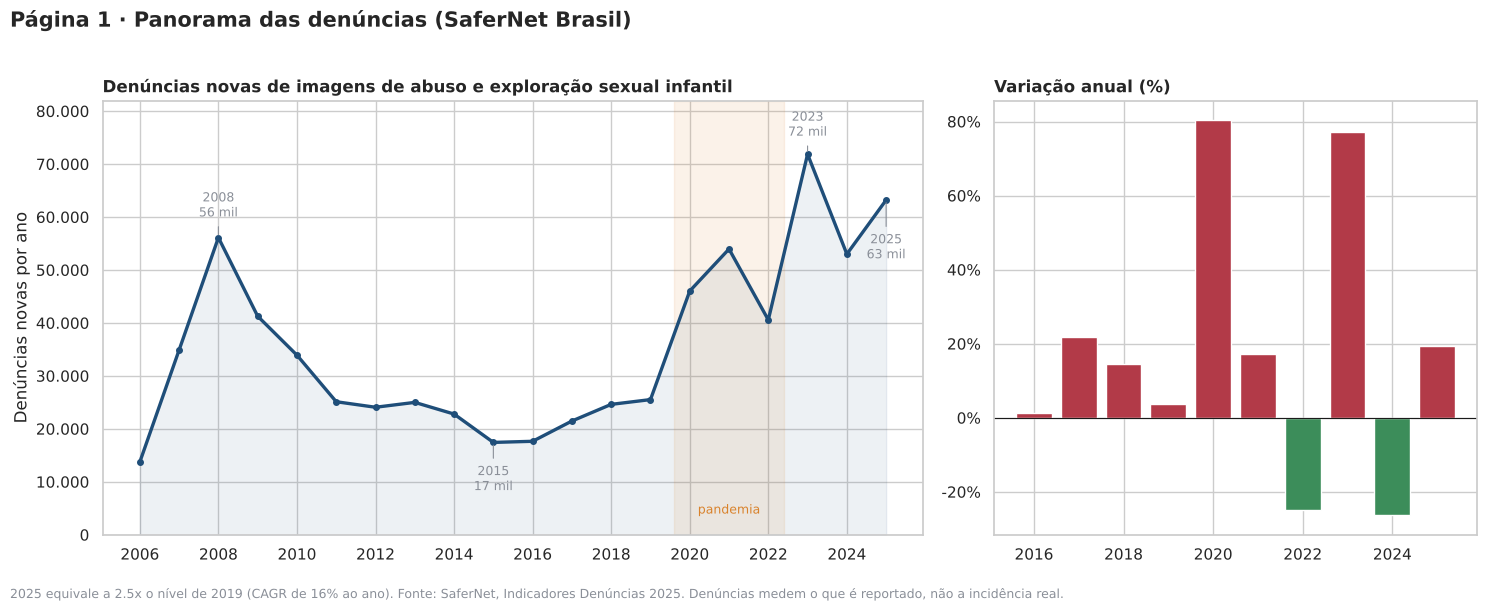

In [11]:
# ===================== Página 1 – Série SaferNet ===================================
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.7, 1]})
a = ax[0]
a.plot(s.index, s.values, color=COR["azul"], lw=2.4, marker="o", ms=4)
a.fill_between(s.index, s.values, color=COR["azul"], alpha=.08)
for ano, txt, dy in [(2008, "2008\n56 mil", 4000), (2015, "2015\n17 mil", -9000), (2023, "2023\n72 mil", 3500), (2025, "2025\n63 mil", -11000)]:
    a.annotate(txt, (ano, s[ano]), xytext=(ano, s[ano] + dy), ha="center", fontsize=9, color=COR["cinza"],
               arrowprops=dict(arrowstyle="-", color=COR["cinza"], lw=.8))
a.axvspan(2019.6, 2022.4, color=COR["laranja"], alpha=.10)
a.text(2021, 4000, "pandemia", ha="center", color=COR["laranja"], fontsize=9)
a.set_title("Denúncias novas de imagens de abuso e exploração sexual infantil", loc="left", fontweight="bold")
a.set_ylabel("Denúncias novas por ano"); a.yaxis.set_major_formatter(mt.FuncFormatter(milhar))
a.set_xticks(range(2006, 2026, 2)); a.set_ylim(0, 82000)

b = ax[1]
v = serie.var_pct.loc[2016:]
b.bar(v.index, v.values, color=[COR["vermelho"] if x > 0 else COR["verde"] for x in v.values])
b.axhline(0, color="k", lw=.8)
b.set_title("Variação anual (%)", loc="left", fontweight="bold")
b.yaxis.set_major_formatter(mt.FuncFormatter(pct)); b.set_xticks(v.index[::2])

fig.suptitle("Página 1 · Panorama das denúncias (SaferNet Brasil)", x=.01, ha="left", fontsize=15, fontweight="bold", y=1.02)
fig.text(.01, -.03, f"2025 equivale a {s[2025]/s[2019]:.1f}x o nível de 2019 (CAGR de {cagr_19_25:.0%} ao ano). "
         "Fonte: SaferNet, Indicadores Denúncias 2025. Denúncias medem o que é reportado, não a incidência real.",
         fontsize=9, color=COR["cinza"])
fig.tight_layout(); fig.savefig(DASH / "01_serie_safernet.png", dpi=150, bbox_inches="tight"); plt.show()

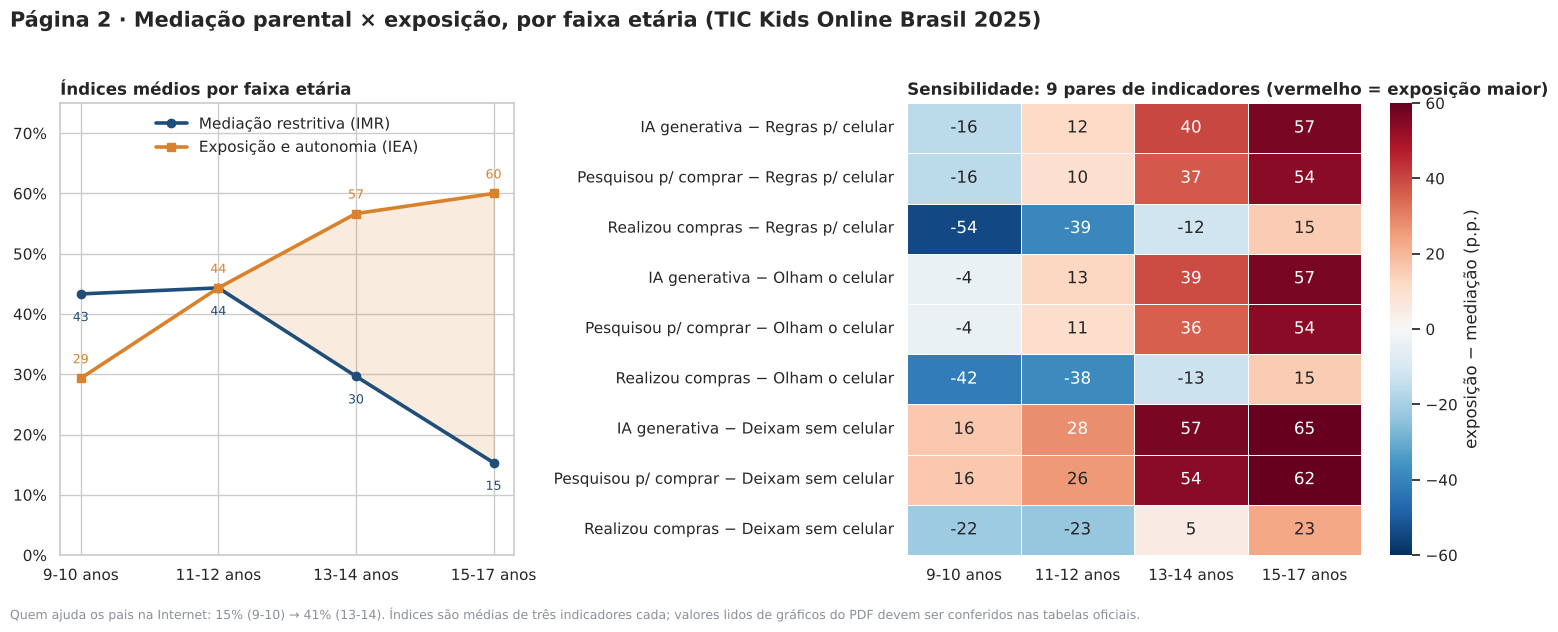

In [12]:
# ===================== Página 2 – Mediação × exposição por faixa etária ============
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.25]})
a = ax[0]
x = np.arange(len(IDADES))
a.plot(x, idx.iloc[:, 0], marker="o", lw=2.6, color=COR["azul"], label="Mediação restritiva (IMR)")
a.plot(x, idx.iloc[:, 1], marker="s", lw=2.6, color=COR["laranja"], label="Exposição e autonomia (IEA)")
a.fill_between(x, idx.iloc[:, 0], idx.iloc[:, 1], where=idx.iloc[:, 1] >= idx.iloc[:, 0],
               color=COR["laranja"], alpha=.15, interpolate=True)
for i, (m_, e_) in enumerate(zip(idx.iloc[:, 0], idx.iloc[:, 1])):
    a.text(i, m_ - 4.5, f"{m_:.0f}", ha="center", color=COR["azul"], fontsize=9)
    a.text(i, e_ + 2.5, f"{e_:.0f}", ha="center", color=COR["laranja"], fontsize=9)
a.set_xticks(x); a.set_xticklabels([f"{i} anos" for i in IDADES]); a.set_ylim(0, 75)
a.yaxis.set_major_formatter(mt.FuncFormatter(pct)); a.legend(loc="upper center", ncol=1, frameon=False)
a.set_title("Índices médios por faixa etária", loc="left", fontweight="bold")

b = ax[1]
sh = sens.drop(columns="1ª faixa em que exposição > mediação")
sns.heatmap(sh, annot=True, fmt=".0f", cmap="RdBu_r", center=0, vmin=-60, vmax=60, linewidths=.5,
            cbar_kws={"label": "exposição − mediação (p.p.)"}, ax=b)
b.set_xticklabels([f"{i} anos" for i in IDADES], rotation=0)
b.set_title("Sensibilidade: 9 pares de indicadores (vermelho = exposição maior)", loc="left", fontweight="bold")
b.set_ylabel("")

fig.suptitle("Página 2 · Mediação parental × exposição, por faixa etária (TIC Kids Online Brasil 2025)",
             x=.01, ha="left", fontsize=15, fontweight="bold", y=1.02)
aj = larga.loc["Ajuda os pais a fazer algo na Internet"]
fig.text(.01, -.03, f"Quem ajuda os pais na Internet: {aj['9-10']:.0f}% (9-10) → {aj['13-14']:.0f}% (13-14). "
         "Índices são médias de três indicadores cada; valores lidos de gráficos do PDF devem ser conferidos nas tabelas oficiais.",
         fontsize=9, color=COR["cinza"])
fig.tight_layout(); fig.savefig(DASH / "02_mediacao_x_exposicao.png", dpi=150, bbox_inches="tight"); plt.show()

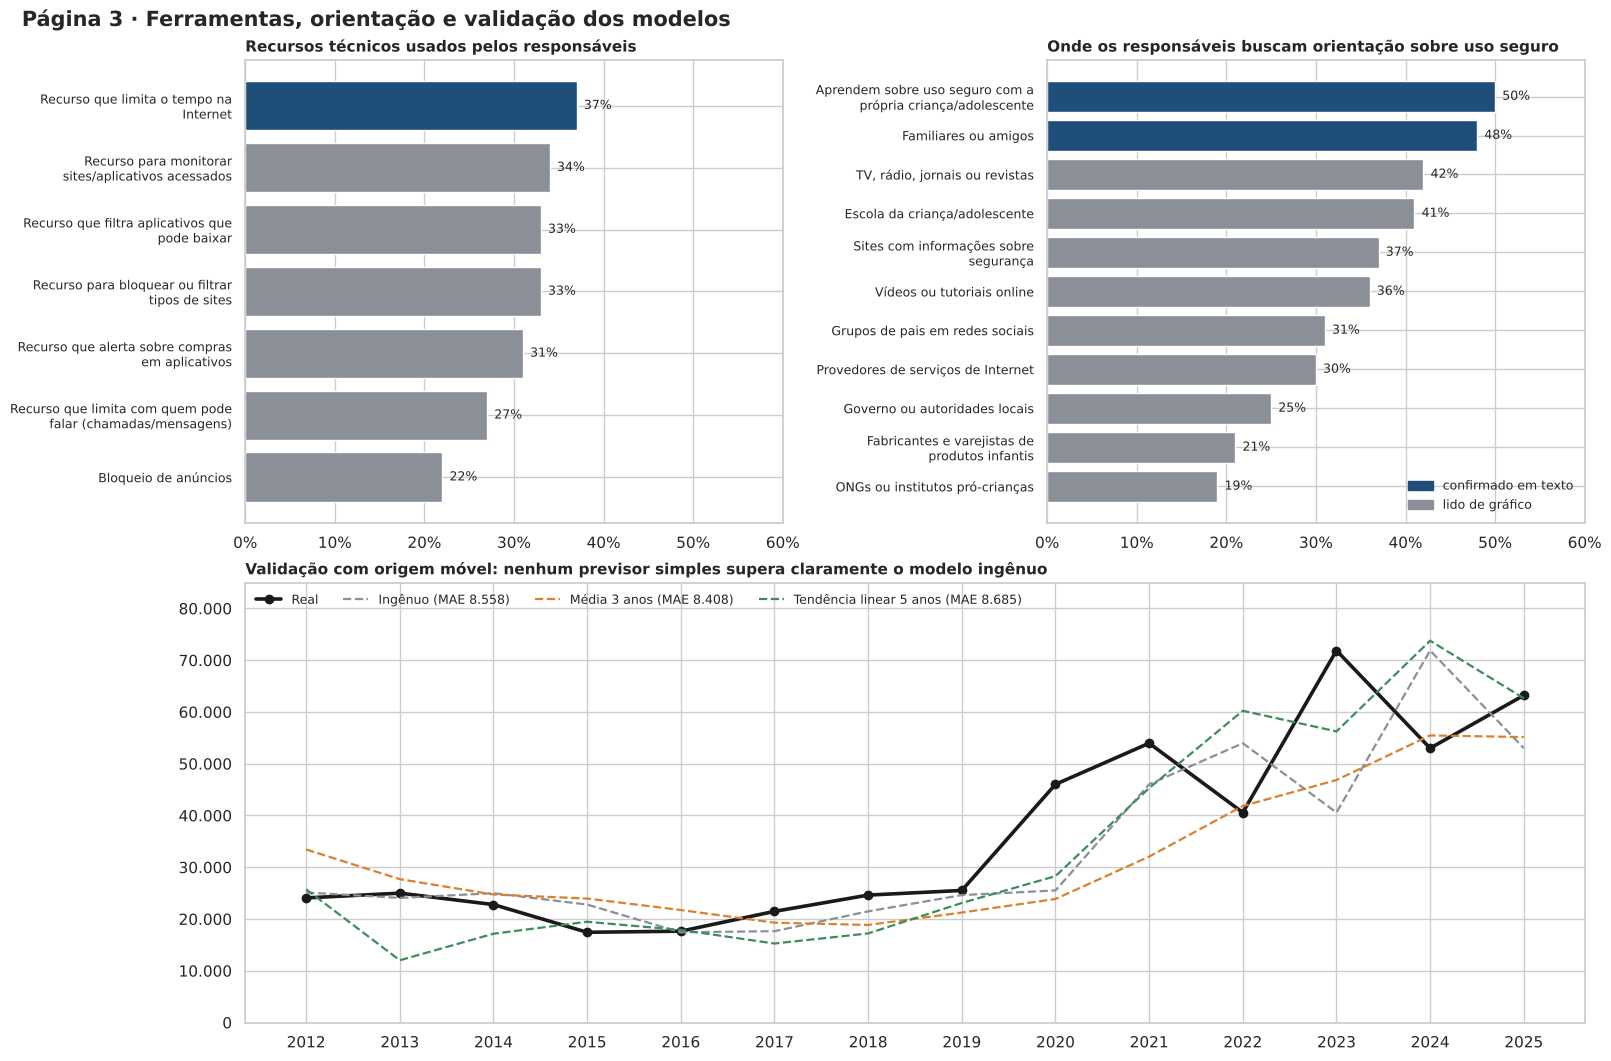

In [13]:
# ===================== Página 3 – Ferramentas, orientação e validação ==============
import textwrap
from matplotlib.patches import Patch
fig = plt.figure(figsize=(16, 10.5), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.95])
cores = {"confirmado_texto": COR["azul"], "leitura_grafico": COR["cinza"]}

def barras(a, bloco, titulo):
    d = tot[tot.bloco == bloco].sort_values("valor_pct")
    rot = [textwrap.fill(x, 34) for x in d.indicador]
    a.barh(rot, d.valor_pct, color=d.confianca.map(cores))
    for y_, v_ in enumerate(d.valor_pct): a.text(v_ + .8, y_, f"{v_}%", va="center", fontsize=9)
    a.set_xlim(0, 60); a.xaxis.set_major_formatter(mt.FuncFormatter(pct))
    a.tick_params(axis="y", labelsize=9)
    a.set_title(titulo, loc="left", fontweight="bold", fontsize=11)
    return a

a1 = barras(fig.add_subplot(gs[0, 0]), "mediacao_tecnica", "Recursos técnicos usados pelos responsáveis")
a2 = barras(fig.add_subplot(gs[0, 1]), "fonte_orientacao", "Onde os responsáveis buscam orientação sobre uso seguro")
a2.legend(handles=[Patch(color=COR["azul"], label="confirmado em texto"), Patch(color=COR["cinza"], label="lido de gráfico")],
          loc="lower right", frameon=False, fontsize=9)

c = fig.add_subplot(gs[1, :])
c.plot(bt.index, bt.real, color="k", lw=2.6, marker="o", label="Real")
c.plot(bt.index, bt.ingenuo, color=COR["cinza"], lw=1.6, ls="--", label=f"Ingênuo (MAE {milhar(aval.loc['ingenuo','MAE'])})")
c.plot(bt.index, bt.media3, color=COR["laranja"], lw=1.6, ls="--", label=f"Média 3 anos (MAE {milhar(aval.loc['media3','MAE'])})")
c.plot(bt.index, bt.tendencia5, color=COR["verde"], lw=1.6, ls="--", label=f"Tendência linear 5 anos (MAE {milhar(aval.loc['tendencia5','MAE'])})")
c.yaxis.set_major_formatter(mt.FuncFormatter(milhar)); c.set_xticks(bt.index); c.set_ylim(0, 85000)
c.set_title("Validação com origem móvel: nenhum previsor simples supera claramente o modelo ingênuo", loc="left", fontweight="bold", fontsize=11)
c.legend(frameon=False, ncol=4, loc="upper left", fontsize=9)

fig.suptitle("Página 3 · Ferramentas, orientação e validação dos modelos", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.savefig(DASH / "03_ferramentas_e_validacao.png", dpi=150); plt.show()

### Plano de implementação (como manter o projeto)

1. **Atualização anual.** A SaferNet publica os indicadores no Dia da Internet Segura (fevereiro) e o Cetic.br divulga o TIC Kids
   Online em outubro. Basta ajustar `scripts/criar_dados.py` e reexecutar o notebook.
2. **Conferência das linhas `leitura_grafico`** contra as tabelas oficiais antes de cada entrega.
3. **Microdados.** Com o acesso aos microdados do TIC Kids, trocar a análise por faixa etária por modelagem em nível individual
   (K-means de perfis de mediação; classificação de quem não usa recurso técnico).
4. **Ligação com o TCC.** A matriz de avaliação das cinco plataformas (usabilidade, IA, detecção de risco, conformidade) pode entrar como
   terceira tabela. Hipótese de trabalho para o capítulo de resultados: as ferramentas precisam **se adaptar à idade**, porque a mediação
   restritiva cai enquanto a autonomia cresce, e o **diálogo** conta tanto quanto o bloqueio.

### Referências das fontes de dados

- SAFERNET BRASIL. *Indicadores Denúncias 2025.* Disponível em: arquivos.safernet.org.br/pdfs/INDICADORES-DenunciasSaferNet2025.pdf.
- CETIC.BR/NIC.BR. *TIC Kids Online Brasil 2025 – Principais Resultados.* São Paulo, 22 out. 2025. Disponível em: cetic.br/media/analises/tic_kids_online_brasil_2025_principais_resultados.pdf.
- FUNDAÇÃO TELEFÔNICA VIVO. *Nota técnica: TIC Kids Online Brasil 2025.* 31 out. 2025.
- CHAPMAN, P. et al. *CRISP-DM 1.0: Step-by-step data mining guide.* 2000.